# FoodHub Order Analysis — Exploratory Data Analysis

**MIT Applied AI & Data Science Program — Foundations for Data Science Project**
Author: Sauraj Karki

Exploratory analysis of 1,898 food-delivery orders from FoodHub, a New York food aggregator app. The goal is to understand restaurant demand and delivery performance, and to recommend ways to improve the business.

### Key findings at a glance

| Question | Answer |
| --- | --- |
| Orders / columns | 1,898 orders × 9 columns, no missing values |
| Unrated orders | 736 (38.8%) |
| Top restaurants | Shake Shack (219), The Meatball Shop (132), Blue Ribbon Sushi (119) |
| Most popular weekend cuisine | American |
| Orders over $20 | 29.24% |
| Mean delivery time | 24.16 min (weekday 28.34 vs weekend 22.47) |
| Orders taking > 60 min end-to-end | 10.54% |
| Net revenue (25% on >$20, 15% on >$5) | $6,166.30 |
| Restaurants qualifying for promotion | Shake Shack, The Meatball Shop, Blue Ribbon Sushi, Blue Ribbon Fried Chicken |

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [2]:
import os

# The CSV ships with this repository in data/; fall back to the working directory (e.g. Colab upload)
DATA_PATH = os.path.join("..", "data", "foodhub_order.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = "foodhub_order.csv"

df = pd.read_csv(DATA_PATH)
df.head()   # first 5 rows

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


#### Observations:

The DataFrame has 9 columns as mentioned in the Data Dictionary. Data in each row corresponds to the order placed by a customer.

### **Question 1:** How many rows and columns are present in the data?

In [3]:
# shape returns (rows, columns)
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 1898
Number of columns: 9


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used)

In [4]:
# Column names, non-null counts and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
The dataset contains 1,898 records and 9 variables, with no missing values in any column. It mixes numerical variables (order cost, food preparation time and delivery time) and categorical variables (restaurant name, cuisine type and day of the week). Note that `rating` is stored as text (`object`) because unrated orders hold the string "Not given". It has to be converted to a number before any numeric analysis (done in Questions 12 and 13).

### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method.

In [5]:
# Count missing (NaN) values per column
df.isna().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations:
There are no null values. However, `rating` uses the placeholder "Not given" for unrated orders, so missing ratings are hidden rather than truly absent. They are kept as their own category for counting and excluded when averaging ratings.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed?

In [6]:
# Summary statistics (count, mean, std, min, quartiles, max) for numeric columns
df.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


#### Observations: Based on the statistical summary, the minimum food preparation time is 20 minutes, the average is approximately 27.37 minutes, and the maximum is 35 minutes.


### **Question 5:** How many orders are not rated?

In [7]:
# Frequency of each rating value, including the "Not given" placeholder
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


#### Observations:
736 orders (38.8%) are not rated.

### Exploratory Data Analysis (EDA)

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.)

### Univariate Analysis

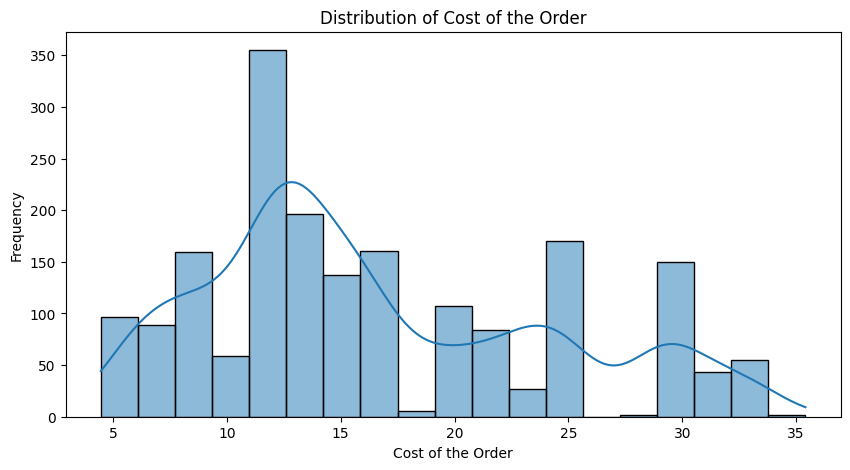

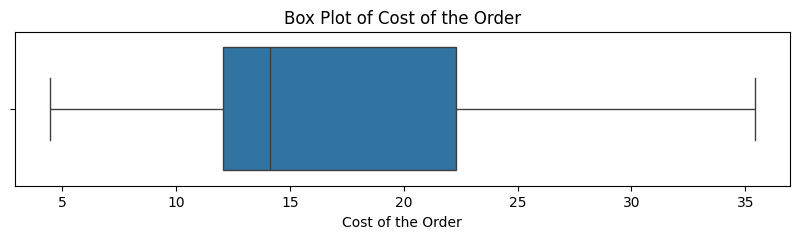

count    1898.000000
mean       16.498851
std         7.483812
min         4.470000
25%        12.080000
50%        14.140000
75%        22.297500
max        35.410000
Name: cost_of_the_order, dtype: float64


In [8]:
def hist_and_box(col, label):
    """Histogram (with KDE) plus a box plot for one numeric column, then its summary stats."""
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {label}')
    plt.xlabel(label)
    plt.ylabel('Frequency')
    plt.show()

    plt.figure(figsize=(10, 2))
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {label}')
    plt.xlabel(label)
    plt.show()

    print(df[col].describe())

# Univariate analysis: cost of the order
hist_and_box('cost_of_the_order', 'Cost of the Order')

#### Observations on Cost of the Order:
* The distribution is right-skewed: most orders are lower in cost, with a tail of more expensive ones. The median ($14.14) sits below the mean ($16.50).
* Order cost ranges from $4.47 to $35.41.

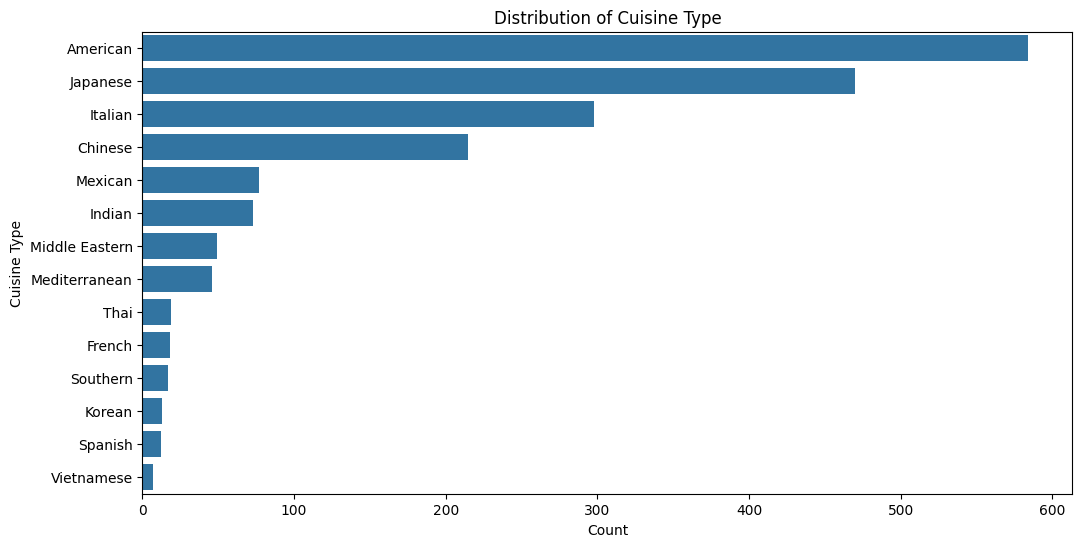

cuisine_type
American          584
Japanese          470
Italian           298
Chinese           215
Mexican            77
Indian             73
Middle Eastern     49
Mediterranean      46
Thai               19
French             18
Southern           17
Korean             13
Spanish            12
Vietnamese          7
Name: count, dtype: int64


In [9]:
# Univariate analysis: cuisine type (sorted by frequency)
plt.figure(figsize=(12, 6))
sns.countplot(y=df['cuisine_type'], order=df['cuisine_type'].value_counts().index)
plt.title('Distribution of Cuisine Type')
plt.xlabel('Count')
plt.ylabel('Cuisine Type')
plt.show()

print(df['cuisine_type'].value_counts())

#### Observations on Cuisine Type:
* American (584), Japanese (470) and Italian (298) dominate, followed by Chinese (215). Together these four make up about 83% of orders.
* The least ordered cuisines are Vietnamese (7), Spanish (12) and Korean (13).

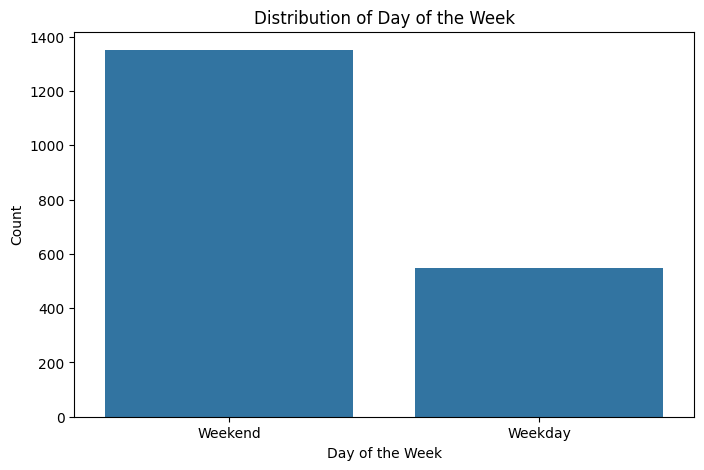

day_of_the_week
Weekend    1351
Weekday     547
Name: count, dtype: int64


In [10]:
# Univariate analysis: weekday vs weekend orders
plt.figure(figsize=(8, 5))
sns.countplot(x=df['day_of_the_week'], order=df['day_of_the_week'].value_counts().index)
plt.title('Distribution of Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Count')
plt.show()

print(df['day_of_the_week'].value_counts())

#### Observations on Day of the Week:
* About 71% of orders (1,351) are placed on weekends, against 547 on weekdays, even though weekends are only 2 of the 7 days.

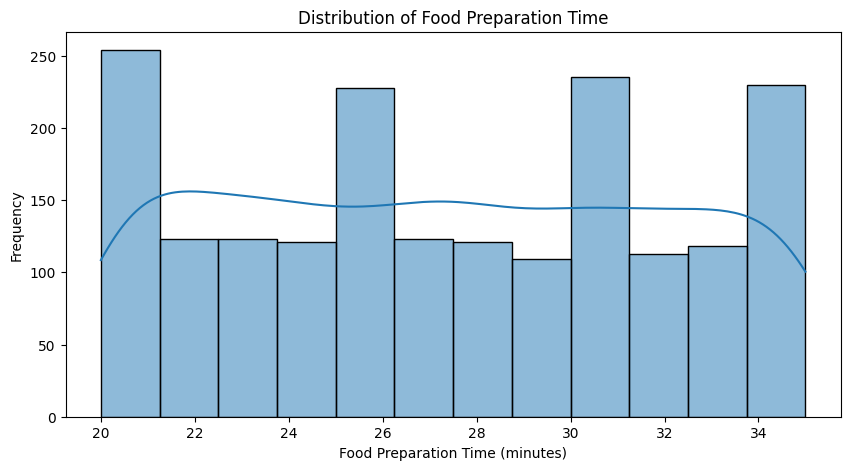

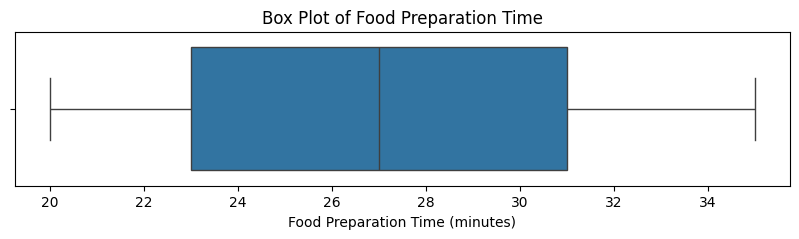

count    1898.000000
mean       27.371970
std         4.632481
min        20.000000
25%        23.000000
50%        27.000000
75%        31.000000
max        35.000000
Name: food_preparation_time, dtype: float64


In [11]:
# Univariate analysis: food preparation time
hist_and_box('food_preparation_time', 'Food Preparation Time (minutes)')

#### Observations on Food Preparation Time:
* The `food_preparation_time` is fairly uniformly distributed between 20 and 35 minutes.
* The average preparation time is about 27.37 minutes.

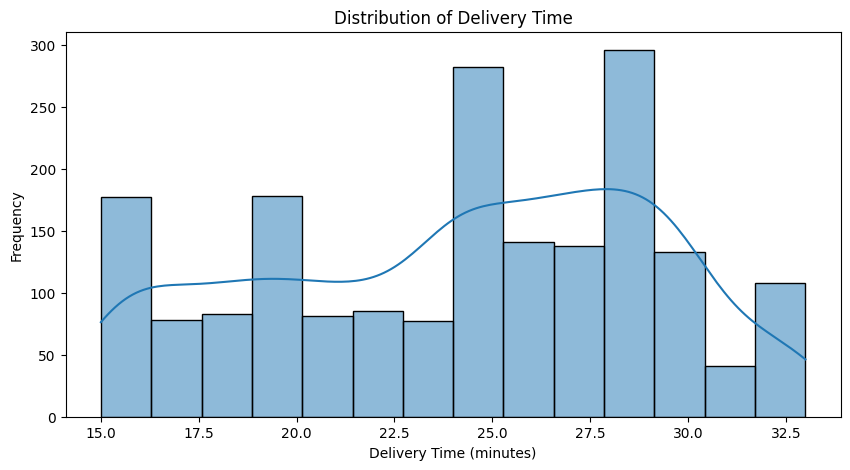

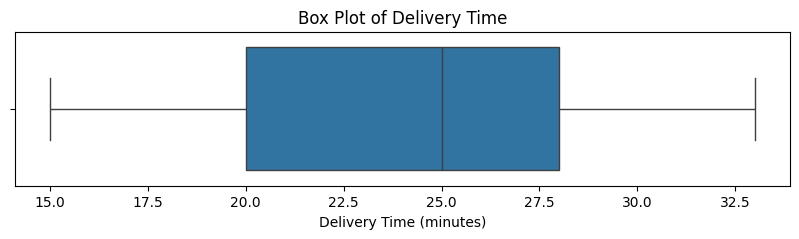

count    1898.000000
mean       24.161749
std         4.972637
min        15.000000
25%        20.000000
50%        25.000000
75%        28.000000
max        33.000000
Name: delivery_time, dtype: float64


In [12]:
# Univariate analysis: delivery time
hist_and_box('delivery_time', 'Delivery Time (minutes)')

#### Observations on Delivery Time:
* The `delivery_time` is also fairly uniformly distributed, ranging from 15 to 33 minutes.
* The average delivery time is about 24.16 minutes.

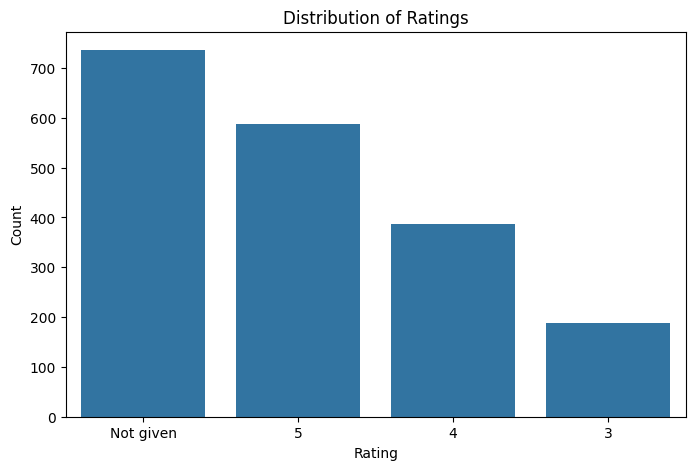

rating
Not given    736
5            588
4            386
3            188
Name: count, dtype: int64


In [13]:
# Univariate analysis: rating
plt.figure(figsize=(8, 5))
sns.countplot(x=df['rating'], order=df['rating'].value_counts().index)
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

print(df['rating'].value_counts())

#### Observations on Rating:
* A significant portion of orders (736) do not have a rating.
* Among rated orders, a rating of '5' is the most common, followed by '4' and '3'.

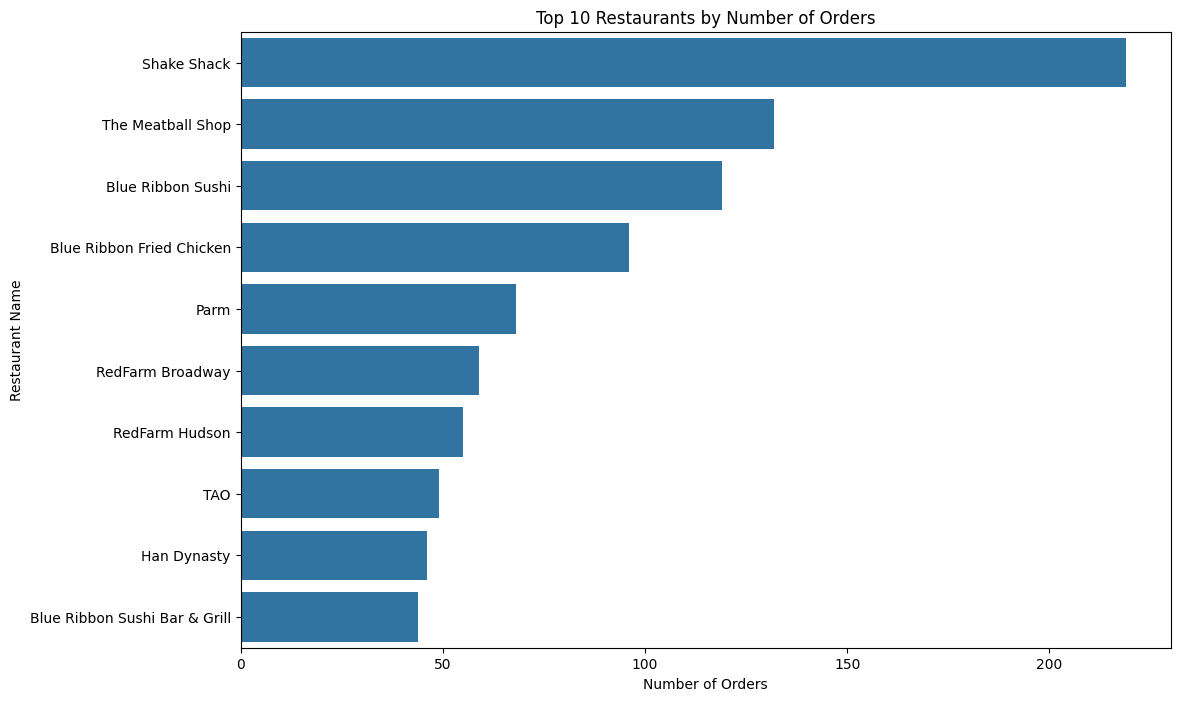

restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
                            ... 
Rye House                      1
Hiroko's Place                 1
Frank Restaurant               1
Sarabeth's West                1
'wichcraft                     1
Name: count, Length: 178, dtype: int64


In [14]:
# Univariate analysis: restaurants (top 10 shown; 178 restaurants in total)
plt.figure(figsize=(12, 8))
sns.countplot(y=df['restaurant_name'], order=df['restaurant_name'].value_counts().head(10).index)
plt.title('Top 10 Restaurants by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')
plt.show()

print(df['restaurant_name'].value_counts())

#### Observations on Restaurant Name:
* There are 178 unique restaurants.
* Demand is highly concentrated: Shake Shack alone has 219 orders, while many restaurants have only one. The plot shows the top 10.

In [15]:
# Identifier columns: are orders unique, and do customers repeat?
print(f"Number of unique order_id: {df['order_id'].nunique()}")
print(f"Number of unique customer_id: {df['customer_id'].nunique()}")
print(f"Total number of orders: {len(df)}")

Number of unique order_id: 1898
Number of unique customer_id: 1200
Total number of orders: 1898


#### Observations on order_id and customer_id:
* `order_id` has 1898 unique values, which is equal to the total number of rows, confirming it as a unique identifier for each order.
* `customer_id` has 1200 unique values, indicating that some customers have placed multiple orders.

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received?

In [16]:
# Top 5 restaurants by number of orders
top_5_restaurants = df['restaurant_name'].value_counts().head(5)
print(top_5_restaurants)

restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
Name: count, dtype: int64


#### Observations: The top restaurants in terms of the numbers of orders received are `Shake Shack` , `The Meatball Shop` , `Blue Ribbon Sushi` , `Blue Ribbon Fried Chicken` and `Parm` .

### **Question 8**: Which is the most popular cuisine on weekends?

In [17]:
# Most frequent cuisine among weekend orders
weekend_orders = df[df['day_of_the_week'] == 'Weekend']
most_popular_cuisine_weekend = weekend_orders['cuisine_type'].value_counts().idxmax()
most_popular_cuisine_weekend

'American'

#### Observations: The most popular cuisine on weekends is **American**.


### **Question 9**: What percentage of the orders cost more than 20 dollars?

In [18]:
# Share of orders costing more than $20
orders_cost_more_than_20 = df[df['cost_of_the_order'] > 20]
percentage = (len(orders_cost_more_than_20) / len(df)) * 100
percentage

29.24130663856691

#### Observations: The percentage of orders costing more than 20 dollars is 29.24%


### **Question 10**: What is the mean order delivery time?

In [19]:
mean_delivery_time = df['delivery_time'].mean()
print(mean_delivery_time)

24.161749209694417


#### Observations: The mean order delivery time is  ***24.16 minutes***


### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed.

In [20]:
# Customers with the most orders
top_3_customers = df['customer_id'].value_counts().head(3)
print("Top 3 most frequent customers and their order counts:")
print(top_3_customers)

Top 3 most frequent customers and their order counts:
customer_id
52832    13
47440    10
83287     9
Name: count, dtype: int64


#### Observations:
The **top three** most frequent customers are **customer_id** `52832` (13 orders), `47440` (10 orders) and `83287` (9 orders).

### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables)


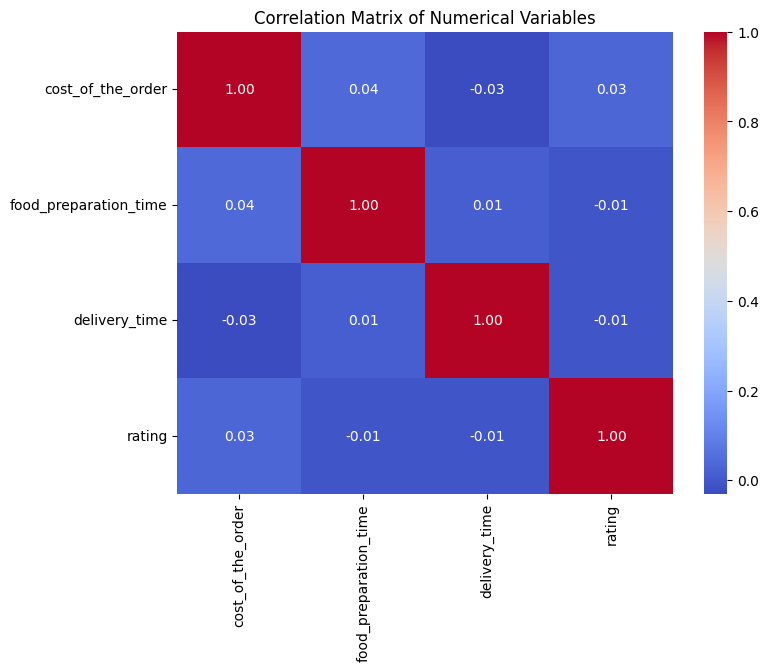

In [21]:
# Correlation heatmap for the numeric variables
df_corr = df.copy()   # work on a copy so the original column stays untouched

# "Not given" -> NaN so rating can be treated as a number
df_corr['rating'] = df_corr['rating'].replace('Not given', np.nan)
df_corr['rating'] = pd.to_numeric(df_corr['rating'])

num_cols = ['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'rating']

# pandas computes each pairwise correlation on the rows where both values exist
corr = df_corr[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

The correlation matrix shows the strength and direction of linear relationships between numerical variables. Overall, the correlations are very weak, with values close to zero across all variable pairs. This indicates minimal linear association between order cost, food preparation time, delivery time, and customer rating. Order cost shows negligible correlation with both preparation and delivery time, suggesting that higher-priced orders do not necessarily require more time to prepare or deliver. Similarly, customer ratings display almost no correlation with operational time variables, implying that ratings may be influenced by factors beyond time, such as food quality or service experience. Overall, the matrix suggests that these variables largely operate independently.



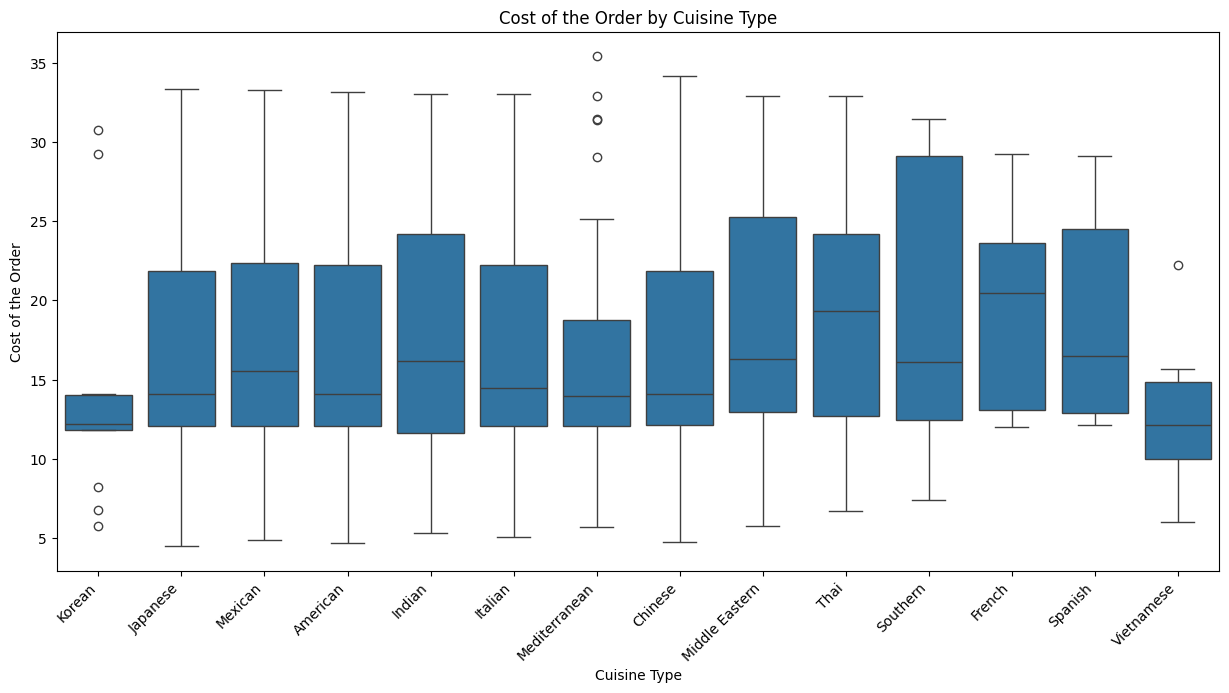

In [22]:
# Order cost by cuisine type
plt.figure(figsize=(15, 7))
sns.boxplot(x='cuisine_type', y='cost_of_the_order', data=df)
plt.xticks(rotation=45, ha='right')
plt.title('Cost of the Order by Cuisine Type')
plt.xlabel('Cuisine Type')
plt.ylabel('Cost of the Order')
plt.show()

The boxplot presents the distribution of order costs across various cuisine types, highlighting differences in median values, variability, and outliers. The median cost varies notably by cuisine, indicating that cuisine type influences customer spending behavior. French, Thai, Middle Eastern, and Southern cuisines exhibit higher median order costs, suggesting these cuisines are generally associated with higher-priced or larger orders.

In contrast, Korean and Vietnamese cuisines show lower median costs and tighter distributions, reflecting more affordable and consistent pricing. Cuisines such as Indian, Italian, American, and Mexican demonstrate moderate median costs with wider interquartile ranges, indicating a diverse range of order values and menu options. The presence of high-cost outliers in cuisines like Mediterranean and Chinese suggests occasional premium or large-group orders that contribute disproportionately to revenue.

Overall, the figure indicates that order cost varies significantly across cuisine types. These insights can support FoodHub in identifying high-revenue cuisines, designing targeted promotions, and optimizing pricing and commission strategies.

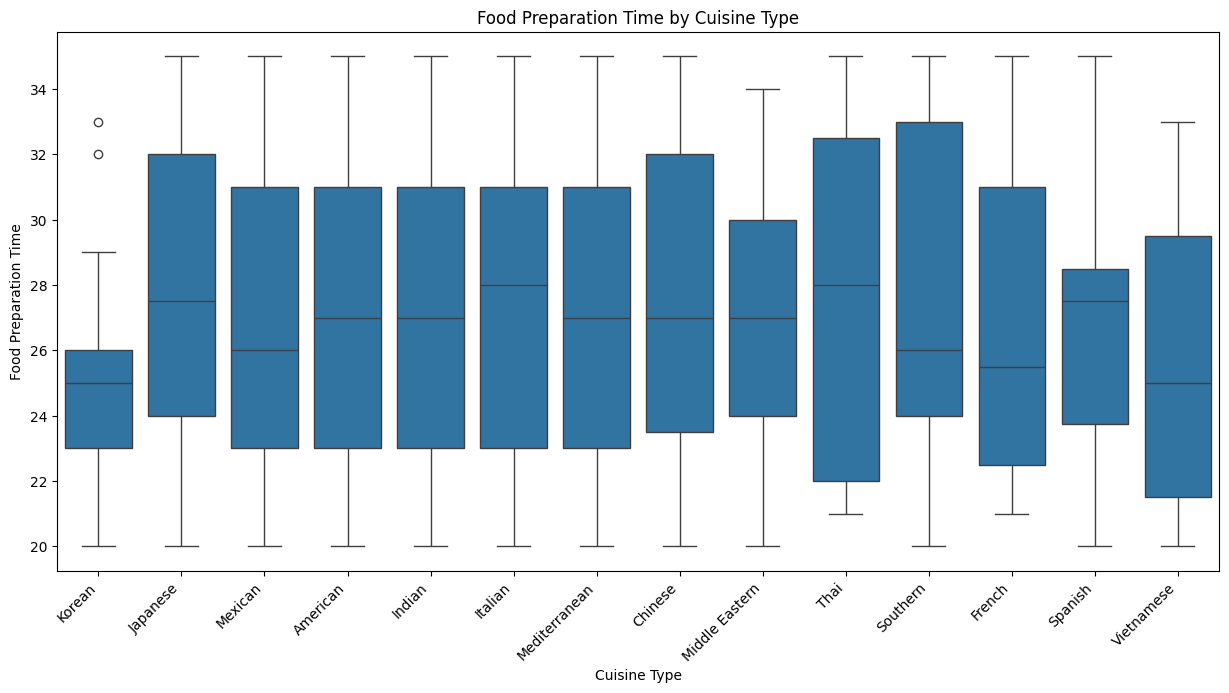

In [23]:
# Food preparation time by cuisine type
plt.figure(figsize=(15, 7))
sns.boxplot(x='cuisine_type', y='food_preparation_time', data=df)
plt.xticks(rotation=45, ha='right')
plt.title('Food Preparation Time by Cuisine Type')
plt.xlabel('Cuisine Type')
plt.ylabel('Food Preparation Time')
plt.show()

The boxplot shows food preparation times by cuisine. Most cuisines have similar medians, between 25 and 28 minutes, so preparation requirements are broadly comparable. Italian and Thai have the highest medians (28 minutes), and Thai also shows the widest spread. Korean, Vietnamese and French have the lowest medians (25–25.5 minutes), and Korean preparation times are notably consistent (an interquartile range of only 3 minutes). Overall, differences in preparation time across cuisines are modest.

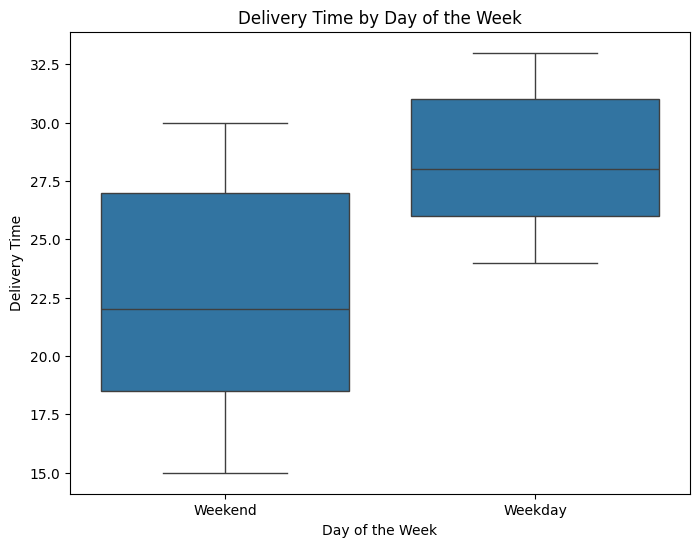

In [24]:
# Delivery time on weekdays vs weekends
plt.figure(figsize=(8, 6))
sns.boxplot(x='day_of_the_week', y='delivery_time', data=df)
plt.title('Delivery Time by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Delivery Time')
plt.show()

The boxplot compares delivery times between weekdays and weekends. Weekend deliveries show a lower median delivery time but a wider spread, indicating greater variability in delivery performance. This suggests that while some weekend orders are delivered quickly, others experience longer delays. In contrast, weekday deliveries have a higher median delivery time with a more concentrated distribution, reflecting more consistent delivery durations. The greater variability observed during weekends may be due to fluctuations in order volume, traffic conditions, or delivery partner availability. Overall, the figure highlights that delivery time patterns differ by day type, suggesting the need for improved delivery capacity and scheduling during weekends to reduce variability and maintain service consistency.

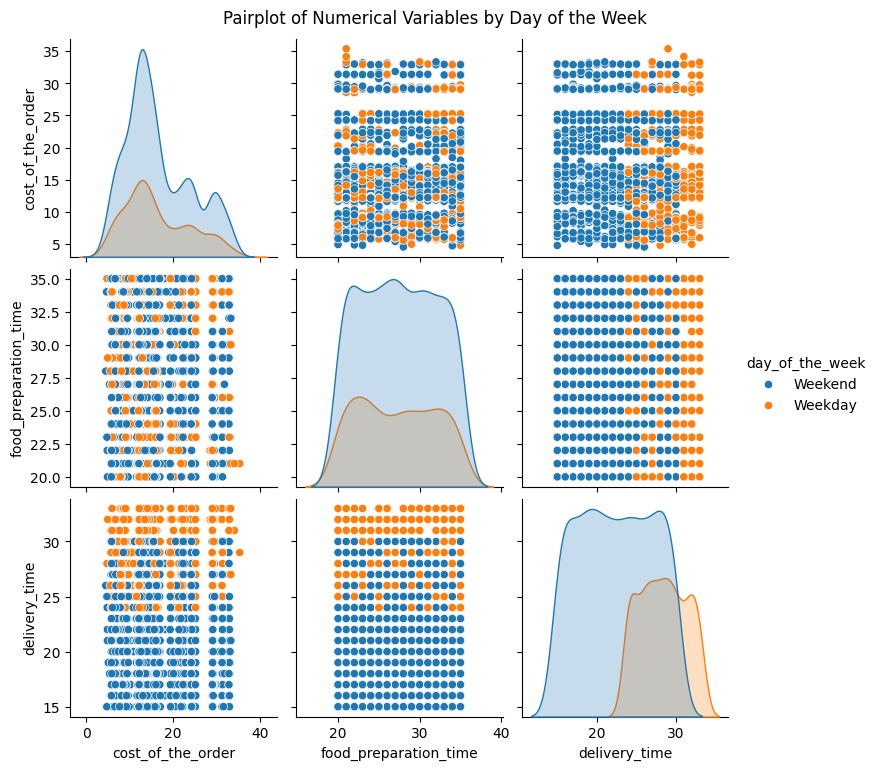

In [25]:
# Pairwise relationships between the numeric variables, coloured by weekday/weekend
sns.pairplot(df[['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'day_of_the_week']],
             hue='day_of_the_week', diag_kind='kde')
plt.suptitle('Pairplot of Numerical Variables by Day of the Week', y=1.02)
plt.show()

The pairplot shows order cost, food preparation time and delivery time, split by weekday and weekend. The diagonal density plots show that weekday and weekend orders have very similar distributions for order cost and preparation time, so pricing and kitchen processes are consistent across the week. Delivery time is the exception: weekday orders sit clearly higher (mean 28.3 vs 22.5 minutes).

The scatter plots show no meaningful linear relationship between any pair of these variables. For example, the correlation between preparation time and delivery time is about 0.01, so higher-priced or slower-to-prepare orders do not take longer to deliver. Overall, day of the week is the main factor associated with delivery time.

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer.

In [26]:
# Keep only rated orders and make the rating numeric
rated_orders = df[df['rating'] != 'Not given'].copy()
rated_orders['rating'] = pd.to_numeric(rated_orders['rating'])

# Number of ratings and average rating per restaurant
restaurant_ratings = rated_orders.groupby('restaurant_name').agg(
    rating_count=('rating', 'count'),
    average_rating=('rating', 'mean'),
).reset_index()

# Promotion criteria: more than 50 ratings AND average rating above 4
promotional_restaurants = restaurant_ratings[
    (restaurant_ratings['rating_count'] > 50) &
    (restaurant_ratings['average_rating'] > 4)
]

print("Restaurants fulfilling the criteria for the promotional offer:")
print(promotional_restaurants)

Restaurants fulfilling the criteria for the promotional offer:
               restaurant_name  rating_count  average_rating
16   Blue Ribbon Fried Chicken            64        4.328125
17           Blue Ribbon Sushi            73        4.219178
117                Shake Shack           133        4.278195
132          The Meatball Shop            84        4.511905


#### Observations: On the basis of the above mentioned conditions , the restaurants that qualify for the promotional offer are : `Blue Ribbon Fried Chicken` , `Blue Ribbon Sushi` , `Shake Shack` and `The Meatball Shop`.

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders.

In [27]:
def calculate_revenue(row):
    """FoodHub's commission: 25% on orders over $20, 15% on orders over $5, else nothing."""
    cost = row['cost_of_the_order']
    if cost > 20:
        return cost * 0.25
    elif cost > 5:
        return cost * 0.15
    else:
        return 0

# Commission earned on each order, then the total
df['revenue'] = df.apply(calculate_revenue, axis=1)
net_revenue = df['revenue'].sum()
print("$" + str(net_revenue))

$6166.303


#### Observations: The net revenue generated by the company across all orders is `$6166.30`




### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.)

In [28]:
# End-to-end time = preparation + delivery
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

# Share of orders taking more than an hour in total
orders_gt_60_min = df[df['total_time'] > 60]
percentage_gt_60_min = (len(orders_gt_60_min) / len(df)) * 100
percentage_gt_60_min

10.537407797681771

#### Observations: Percentage of orders taking more than 60 minutes to deliver is `10.54%`



### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends?

In [29]:
# Mean delivery time for weekday vs weekend orders
mean_delivery_time_weekday = df[df['day_of_the_week'] == 'Weekday']['delivery_time'].mean()
mean_delivery_time_weekend = df[df['day_of_the_week'] == 'Weekend']['delivery_time'].mean()

print(mean_delivery_time_weekday)
print(mean_delivery_time_weekend)

28.340036563071298
22.4700222057735


#### Observations:
The mean delivery time is **28.34 minutes on weekdays** and **22.47 minutes on weekends**, so weekday deliveries take about 6 minutes (26%) longer. Possible explanations are heavier weekday traffic or fewer delivery partners on weekdays.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.)

### Conclusions:
This analysis explored customer ordering behaviour and operational performance in the FoodHub dataset.

- **Demand is concentrated.** Four cuisines (American, Japanese, Italian and Chinese) account for about 83% of orders. A handful of restaurants, led by Shake Shack, receive a large share of them, and 71% of orders are placed on weekends.
- **Order value varies by cuisine.** French and Thai have the highest median order cost (about $19–20), while Korean and Vietnamese are the cheapest (about $12). Preparation times are broadly similar across cuisines (median 25–28 minutes).
- **Operational variables are largely independent.** Order cost, preparation time, delivery time and rating show near-zero correlations with each other.
- **Day of the week drives delivery time.** Weekday deliveries take on average about 6 minutes longer than weekend ones (28.3 vs 22.5 minutes), while weekend times are more spread out. About 10.5% of orders take over an hour end to end.
- **Feedback coverage is low.** 38.8% of orders are unrated, which limits how well service quality can be measured.

### Recommendations:

1. **Fix weekday delivery times.** Weekday deliveries average about 6 minutes longer than weekend ones. FoodHub should look at weekday rider availability and routing (for example, adding partners at weekday lunch and dinner peaks). On weekends, where times vary more, demand-based scheduling of delivery partners would make service more consistent. Targeting the 10.5% of orders that take more than an hour end to end is a concrete KPI.

2. **Use cuisine insights for revenue.** Higher-value cuisines such as French and Thai are good candidates for premium promotions or partnerships, since 25% commission applies to orders over $20. The high-volume cuisines (American, Japanese, Italian and Chinese) and the top restaurants should be protected with strong service levels and loyalty offers. The four restaurants that qualified for the promotional offer are natural anchors for advertising.

3. **Grow feedback coverage.** With 38.8% of orders unrated, FoodHub should encourage ratings through small incentives (discounts or loyalty points) or a one-tap prompt after delivery. Better feedback coverage would make quality monitoring and restaurant-level decisions more reliable.